# Plotting reference
Optional support, not additional work to complete. Choose only the example that helps your question. These examples use Titanic so your tornado investigation remains your own.

| Question | Starting view |
|---|---|
| What values are common? | Histogram |
| How do numerical values differ by group? | Boxplot |
| How do two numerical variables relate? | Scatterplot |
| How many records are in each category? | Countplot |
| What proportion has an outcome? | Grouped proportion with an explicit denominator |
| How does something vary over ordered time? | Aggregated time plot with missing periods considered |


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Works when the notebook starts in the repository root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "data/titanic.csv").exists():
    ROOT = ROOT.parent
titanic = pd.read_csv(ROOT / "data/titanic.csv")
sns.set_theme(style="whitegrid", context="talk")


## Distribution


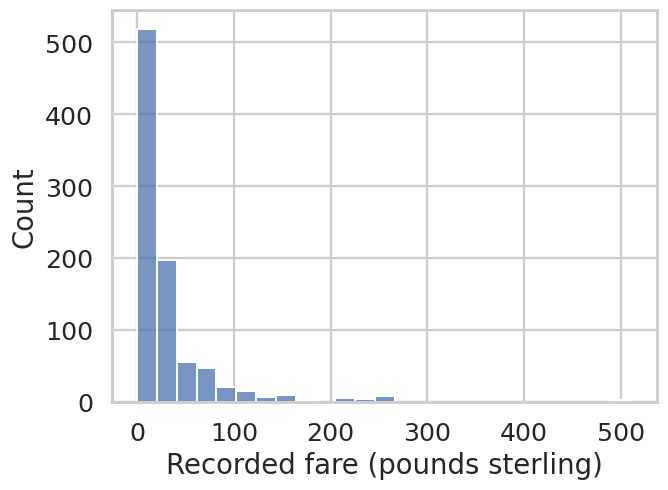

In [2]:
sns.histplot(data=titanic, x="fare", bins=25)
plt.xlabel("Recorded fare (pounds sterling)")
plt.tight_layout()
plt.show()


## Numerical comparisons across categories
This example uses the 714 passengers with observed age. Report exclusions whenever your variables contain missing values.


Using 714 of 891 records


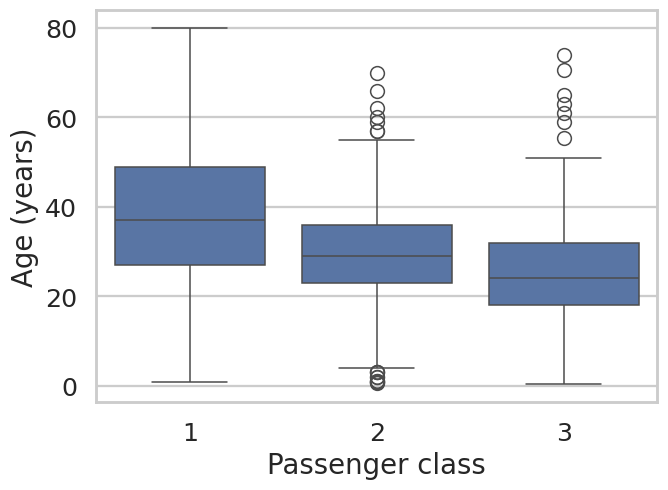

In [3]:
known_age = titanic.dropna(subset=["age"])
print(f"Using {len(known_age)} of {len(titanic)} records")
sns.boxplot(data=known_age, x="pclass", y="age")
plt.xlabel("Passenger class")
plt.ylabel("Age (years)")
plt.tight_layout()
plt.show()


## Relationship, then color
Read the first view, then ask whether adding a category helps. Overlapping points can hide observations.


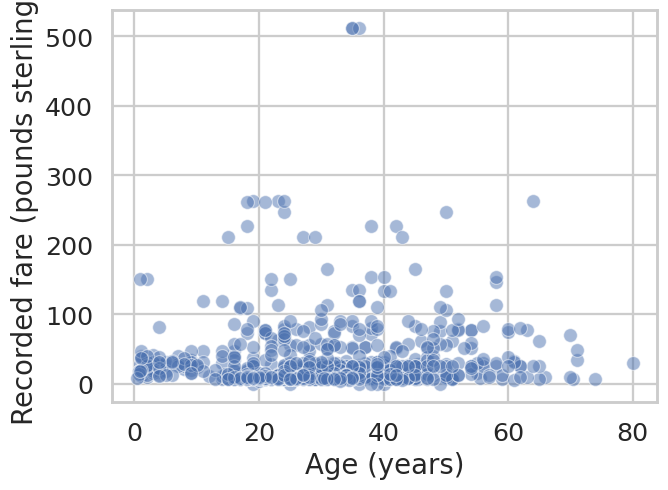

In [4]:
sns.scatterplot(data=known_age, x="age", y="fare", alpha=0.5)
plt.xlabel("Age (years)")
plt.ylabel("Recorded fare (pounds sterling)")
plt.tight_layout()
plt.show()


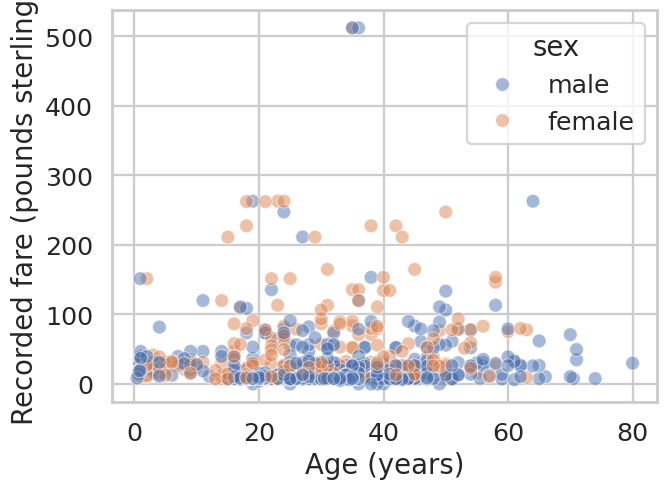

In [5]:
sns.scatterplot(data=known_age, x="age", y="fare", hue="sex", alpha=0.5)
plt.xlabel("Age (years)")
plt.ylabel("Recorded fare (pounds sterling)")
plt.tight_layout()
plt.show()


## Counts and proportions answer different questions


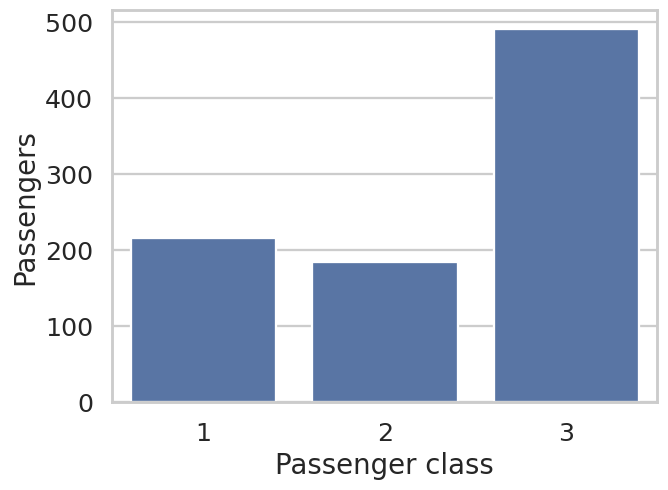

In [6]:
sns.countplot(data=titanic, x="pclass", order=[1, 2, 3])
plt.xlabel("Passenger class")
plt.ylabel("Passengers")
plt.tight_layout()
plt.show()


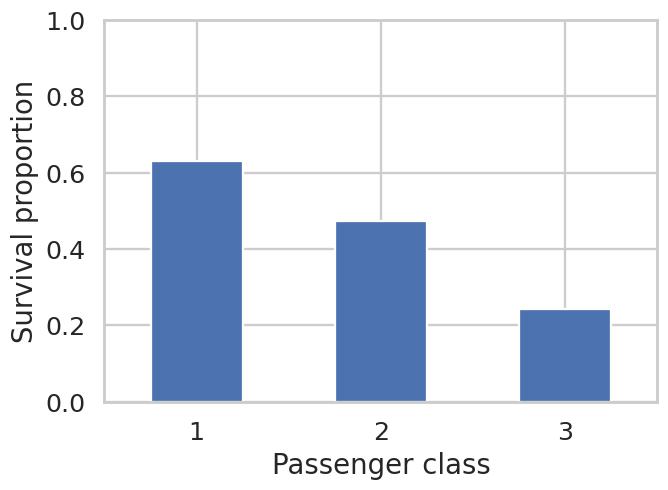

In [7]:
rates = titanic.groupby("pclass")["survived"].mean()
ax = rates.plot.bar(rot=0)
ax.set(xlabel="Passenger class", ylabel="Survival proportion", ylim=(0, 1))
plt.tight_layout()
plt.show()


## Generic patterns for your selected variables
Adapt the placeholders. These are syntax patterns, not ready-to-run cells.

```python
# Filter deliberately, then report how many records remain.
subset = tornadoes.dropna(subset=["your_variable"])
print(len(subset), "of", len(tornadoes))

# Inspect the records behind an unusual value.
tornadoes.sort_values("your_variable", ascending=False).head()

# Aggregate time before drawing a line.
counts = tornadoes.groupby("month").size().reindex(range(1, 13), fill_value=0)
counts.plot.bar()
```

A logarithmic axis can help with positive values spanning a wide range. Check zeros first and explain any exclusions or transformations. Use qualitative color for categories and a continuous color scale for quantities when appropriate. Direct comparison with original units remains useful.
